## 1. Математика

**Задача классификации**: по признакам $x = (x_1,\dots,x_d)$ выбрать класс $y$.

**Теорема Байеса** даёт **апостериорную** вероятность класса:

$$
P(y \mid x_1,\dots,x_d) = \frac{P(x_1,\dots,x_d \mid y)\,P(y)}{P(x_1,\dots,x_d)} \;\propto\; P(y)\,P(x_1,\dots,x_d \mid y)
$$

- $P(y)$ — **априорная** вероятность класса (доля класса в обучающей выборке);
- $P(x\mid y)$ — **правдоподобие**: как выглядят объекты этого класса. Насколько вероятны данные признаки для класса y;
- $P(x)$ вероятность встретить такой набор признаков в принципе. Одинаково для всех классов;

Проблема: оценить $P(x_1,\dots,x_d\mid y)$ в многомерном пространстве почти невозможно (нужно экспоненциально много данных).

**«Наивное» допущение** — признаки **условно независимы** при известном классе:

$$
P(x_1,\dots,x_d \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
\quad\Longrightarrow\quad
\hat y = \arg\max_y \Big[ \log P(y) + \sum_{j=1}^{d} \log P(x_j \mid y) \Big]
$$

Теперь нужно оценить всего $d$ одномерных распределений на класс — это быстро и надёжно даже на малых данных.

### 1.1 Маленький пример: спам / не спам

In [5]:
from collections import Counter

docs   = ["buy cheap pills", "cheap pills now", "meeting tomorrow now", "project meeting notes"]
labels = ["spam", "spam", "ham", "ham"]
vocab  = sorted({w for d in docs for w in d.split()})

def word_prob(w, c, alpha): #
    cnt = Counter(
        word
        for d, l in zip(docs, labels)
        if l == c
        for word in d.split()
    )
    total = sum(cnt.values())
    return (cnt.get(w, 0) + alpha) / (total + alpha * len(vocab))

def posterior(text, alpha):
    joint = {}
    for c in ["spam", "ham"]:
        p = labels.count(c) / len(labels)
        for w in text.split():
            p *= word_prob(w, c, alpha)
        joint[c] = p
    z = sum(joint.values())
    return joint, ({c: v / z for c, v in joint.items()} if z > 0 else None)

query = "cheap pills meeting" 
for a in [1, 0]:
    joint, post = posterior(query, alpha=a)
    print(f"alpha={a}: P(y)*prod P(w|y) = {joint}  ->  posterior = {post}")

alpha=1: P(y)*prod P(w|y) = {'spam': 0.001639941690962099, 'ham': 0.0005466472303206996}  ->  posterior = {'spam': 0.75, 'ham': 0.25}
alpha=0: P(y)*prod P(w|y) = {'spam': 0.0, 'ham': 0.0}  ->  posterior = None


Что тут важно:

- При `alpha=1` (сглаживание Лапласа) всё считается: два «спамных» слова перевешивают одно «неспамное», спам получает бóльшую вероятность.
- При `alpha=0` слово `meeting` ни разу не встретилось в спаме, а `cheap` и `pills` — в не-спаме. Обе вероятности **обнуляются**, и решение принять нельзя. Это **проблема нулевой частоты**

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
cv = CountVectorizer(vocabulary=vocab)
mnb = MultinomialNB(alpha=1).fit(cv.transform(docs), labels)
print("sklearn  :", dict(zip(mnb.classes_, mnb.predict_proba(cv.transform([query]))[0].round(4))))

sklearn  : {np.str_('ham'): np.float64(0.25), np.str_('spam'): np.float64(0.75)}


## 2. Решающие границы: где NB хорош, где плох

Пять простых 2D-датасетов. Цвет фона — вероятность класса (синий ↔ красный), точки — **тестовая** выборка, в заголовке — accuracy на тесте.

Напоминание: граница GaussianNB — **квадратичная** (разные дисперсии у классов дают изогнутую границу), но эллипсы всегда ориентированы вдоль осей (нет ковариации между признаками). Отсюда ожидания:
- «два облака» — отлично;
- **сильно коррелированные признаки** — хуже (нарушена независимость);
- «круги» — вопреки интуиции, NB может справиться: у внутреннего и внешнего кругов разные дисперсии, а это как раз то, что ловит квадратичная граница (в отличие от линейной модели);
- XOR — взаимодействие признаков, которое NB в принципе не видит.

In [9]:
# 1. Для математики и массивов
import numpy as np

# 2. Для графиков
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Генераторы синтетических датасетов
from sklearn.datasets import make_blobs, make_moons, make_circles

# 4. Разделение данных на train/test
from sklearn.model_selection import train_test_split

# 5. Сами модели для сравнения
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 6. Пайплайны и масштабирование (чтобы kNN и ЛогРег работали корректно)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 7. Утилита для отрисовки границ решений (появилась в sklearn 1.1)
from sklearn.inspection import DecisionBoundaryDisplay

In [10]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
RS = 42

# единые цвета
COL = {"Naive Bayes": "#E4572E", "Logistic Regression": "#2E86AB",
       "kNN": "#6A994E", "Decision Tree": "#8D6A9F"}

def make_models(nb=None):
    # Набор простых моделей для сравнения
    return {
        "Naive Bayes":         nb if nb is not None else GaussianNB(),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "kNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RS),
    }

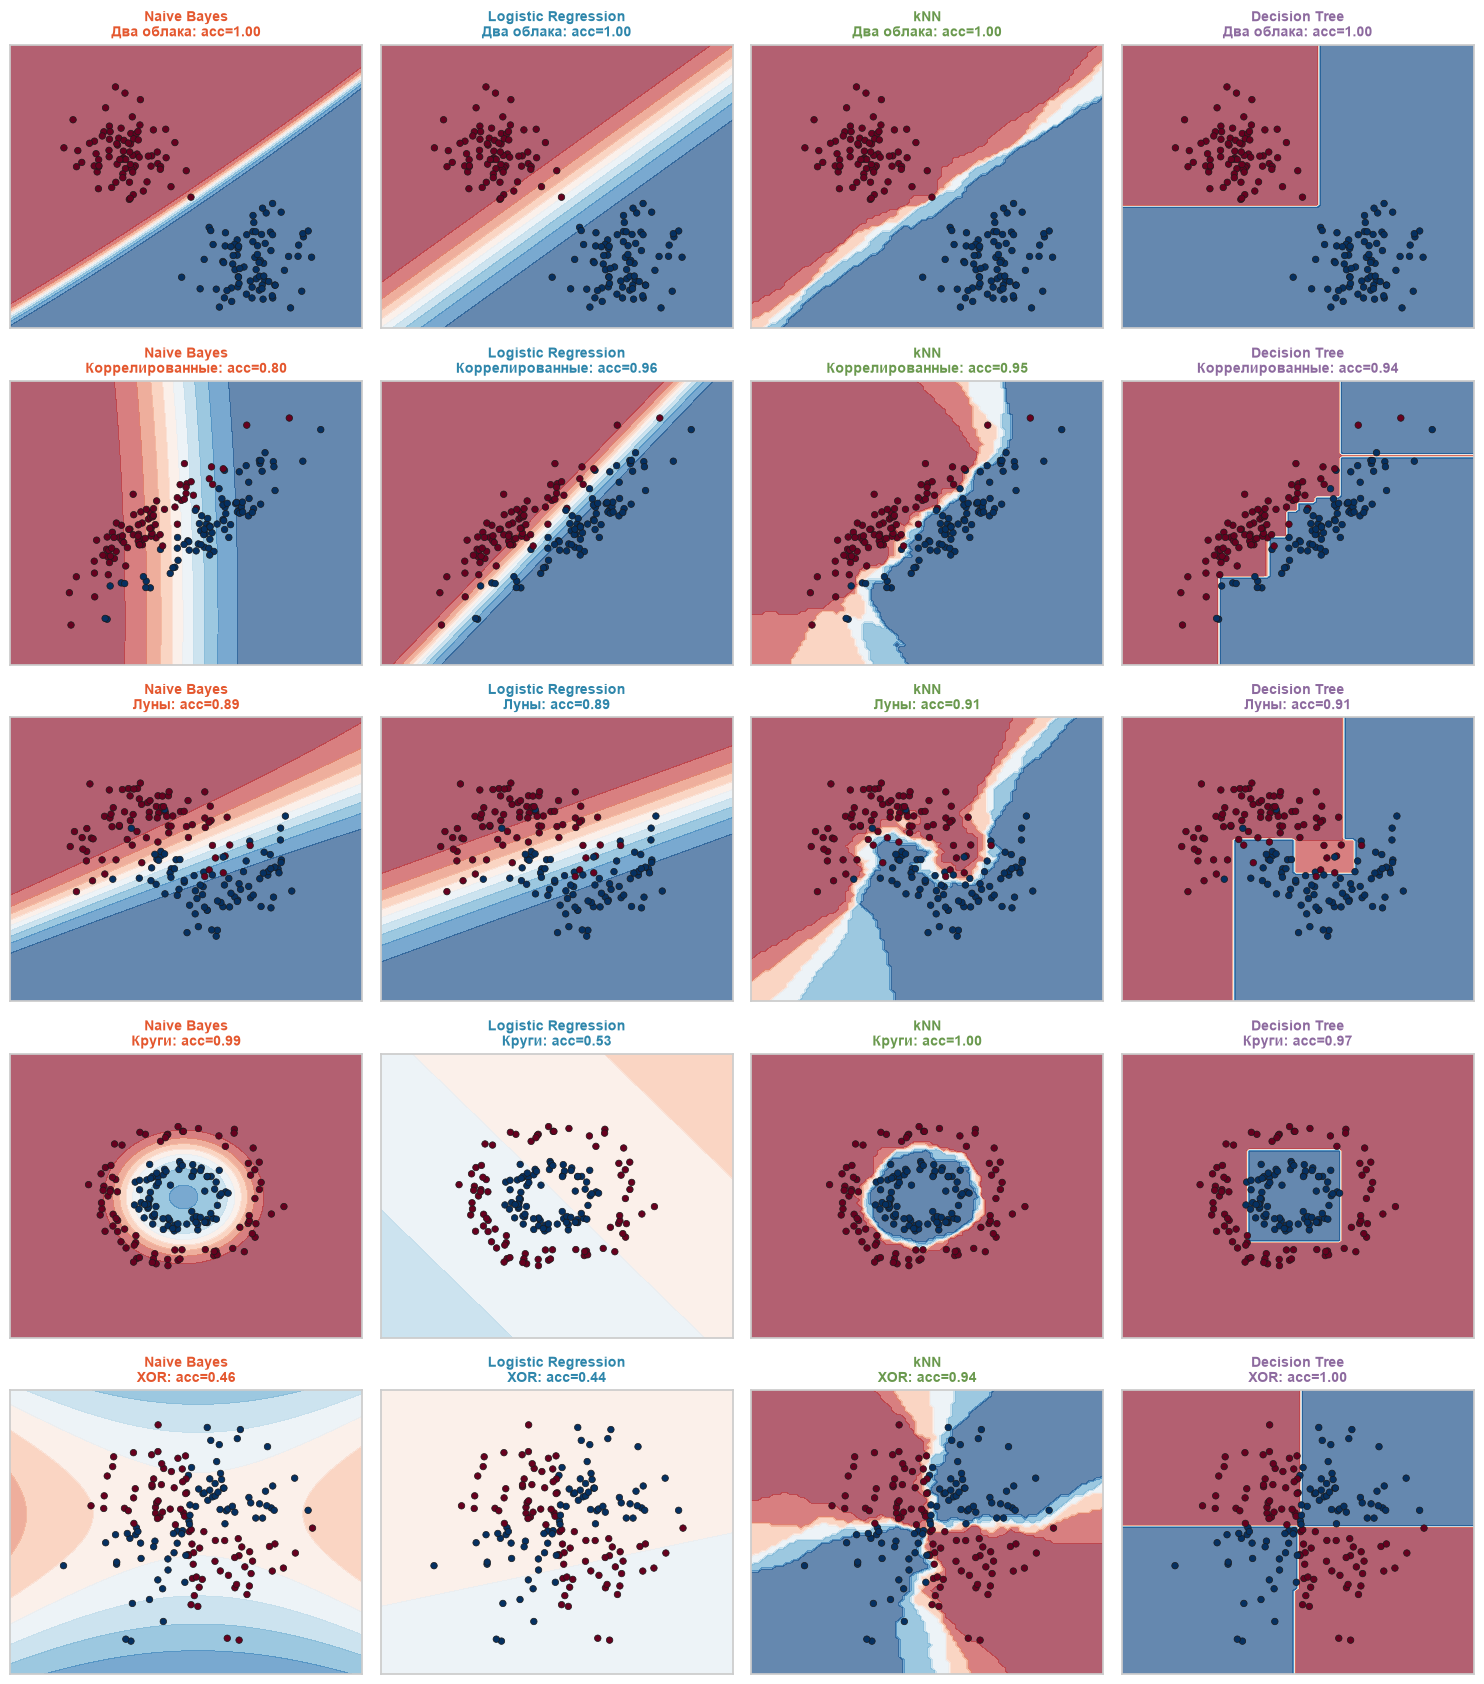

In [17]:
def make_datasets(n=400, seed=RS):
    rng = np.random.RandomState(seed)
    ds = {}
    ds["Два облака"] = make_blobs(n, centers=2, cluster_std=1.6, random_state=seed)
    # коррелированные признаки: общая ковариация с rho=0.9, классы сдвинуты по оси x
    cov = [[1, 0.9], [0.9, 1]]
    X = np.vstack([rng.multivariate_normal([0, 0], cov, n // 2),
                   rng.multivariate_normal([1.5, 0], cov, n // 2)])
    ds["Коррелированные"] = (X, np.r_[np.zeros(n // 2), np.ones(n // 2)].astype(int))
    ds["Луны"]  = make_moons(n, noise=0.25, random_state=seed)
    ds["Круги"] = make_circles(n, noise=0.1, factor=0.45, random_state=seed)
    Xx = rng.randn(n, 2) * 1.2
    ds["XOR"] = (Xx, (Xx[:, 0] * Xx[:, 1] > 0).astype(int))
    return ds

datasets = make_datasets()
fig, axes = plt.subplots(len(datasets), 4, figsize=(15, 3.4 * len(datasets)))
scores_2d = {}
for i, (dname, (X, y)) in enumerate(datasets.items()):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=RS, stratify=y)
    for j, (mname, model) in enumerate(make_models().items()):
        model.fit(Xtr, ytr)
        acc = model.score(Xte, yte)
        scores_2d[(dname, mname)] = acc
        ax = axes[i, j]
        DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict_proba", ax=ax,
                                               cmap="RdBu", alpha=0.65, levels=np.linspace(0, 1, 11),
                                               xlabel="", ylabel="")
        ax.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap="RdBu", edgecolor="k", s=22, linewidth=0.5)
        ax.set_title(f"{mname}\n{dname}: acc={acc:.2f}", fontsize=10, color=COL[mname])
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Что видно на картинках**

- **Два облака:** все модели хороши, NB даёт плавную границу — это «идеальный случай» для него.
- **Коррелированные:** NB заметно проигрывает Logistic Regression: он «видит» два независимых признака и не понимает, что разделяющая информация спрятана в их *сочетании*.
- **Луны:** NB и Logistic Regression дают похожий результат, kNN и дерево чуть лучше — у них нет жёсткого допущения о форме классов.
- **Круги:** сюрприз — NB справляется почти идеально (≈0.99), а Logistic Regression проваливается (≈0.5): линейной границей концентрические классы не разделить, а у NB граница квадратичная. Но это «везение», связанное с тем, что классы различаются дисперсией вокруг общего центра.
- **XOR:** NB (≈0.46) и Logistic Regression — на уровне случайного угадывания; классы различаются *сочетанием* знаков двух признаков, а NB смотрит на признаки по отдельности. kNN и дерево справляются.
- **Фон NB очень «резкий»** (особенно на «двух облаках» и «коррелированных»): переходы от красного к синему происходят на узкой полосе. Это первый намёк на то, что вероятности NB слишком уверенные (раздел 4).